# How often does it pay to go for it on 4th down?
**Project 1 – Applied Probability.** Which rule for when to go for it on 4th down wins the most games?
We estimate probabilities from NFL play-by-play data (2018–2025), simulate whole games as a Markov chain, and compare
strategies with Monte Carlo.

This notebook only **shows** the results. The simulations are run in `compute.ipynb`, which saves `results/results.json`.

In [22]:
import pandas as pd
import model
import plots

params = model.estimate(model.load_data())          # probabilities from the data (a few seconds)
results = model.load_results("results.json")        # simulation results from compute.ipynb
best_policy = model.policy_from_candidate(results["best"], results["fg_range"])
print(f"Best strategy: {results['best_name']}  (field goals up to {results['best_kick_distance']} yards)")
results["final"].loc[[results["best_name"]], ["p̂", "diff (pp)", "diff lower", "diff upper"]].round(3)

Best strategy: ≤5 yd & pos ≤80 + no man's land 35–50 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤2 drives) + leading late: no go at pos ≥50 (≤2 drives) | else kick  (field goals up to 57 yards)


,p̂,diff (pp),diff lower,diff upper
≤5 yd & pos ≤80 + no man's land 35–50 (≤6 yd) + trailing (≤2 drives) + score-changing FG (≤2 drives) + leading late: no go at pos ≥50 (≤2 drives) | else kick,0.542,4.008,3.428,4.588


## 1. Probabilities from the data
**Yards per play.** Yards gained $Y$ is skewed: a point mass at 0 (mostly incomplete passes) and a long right tail.
The simulator stores every real play per (down, yards to go) and **samples** from it; 3rd and 4th down are pooled.

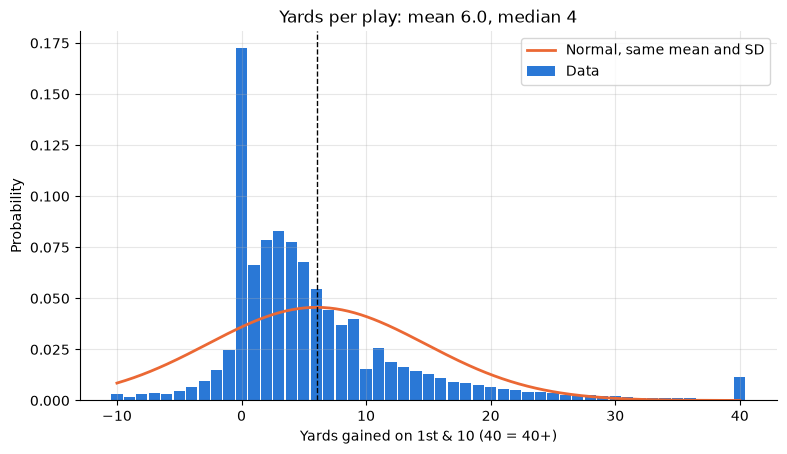

In [23]:
plots.yards_per_play(params)

**Probability of a 1st down**, $p(d) = P(\text{1st down} \mid d)$: a proportion per $d$, standard error $\sqrt{\hat p(1-\hat p)/n} < 0.01$.

In [24]:
params["p_first_down"].loc[1:10].T.round(3)

ydstogo,1,2,3,4,5,6,7,8,9,10
mean,0.7,0.576,0.529,0.488,0.434,0.429,0.384,0.355,0.305,0.294
count,5641.0,3456.000,3178.000,3034.000,3092.000,2891.000,2731.000,2459.000,2079.000,2588.000


**Field goals.** $p_{FG}(x)$ comes from a **logistic regression** $p(x) = 1/(1+e^{-(\beta_0+\beta_1 x)})$,
fitted by maximum likelihood to every kick ($x \approx pos + 18$). The dots show the raw make rate per distance.

**Punts** are drawn only from real punts kicked within ±5 yards of the same spot: near midfield punters aim to
pin the opponent deep rather than kick far, so a punt from the 40 rarely ends in a touchback.

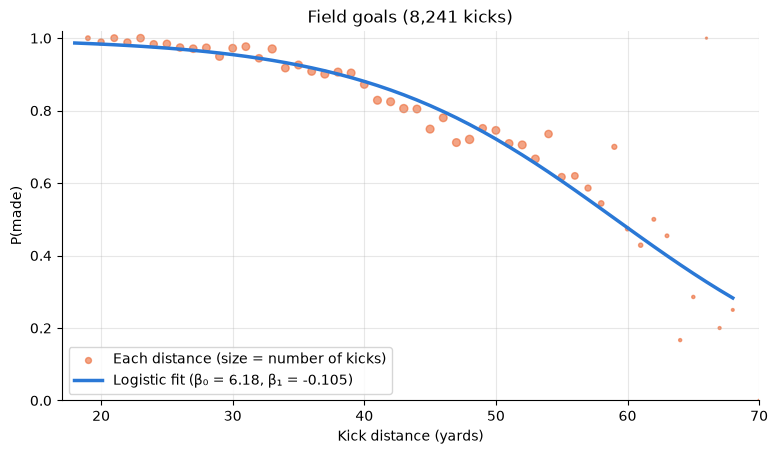

In [25]:
plots.field_goals(params)

**Real coaches** (strategy 1, and always the opponent): $P(\text{go} \mid \text{yards to go, pos})$ per cell.
Coaches almost always go on 4th & 1 around midfield, but rarely on their own half.

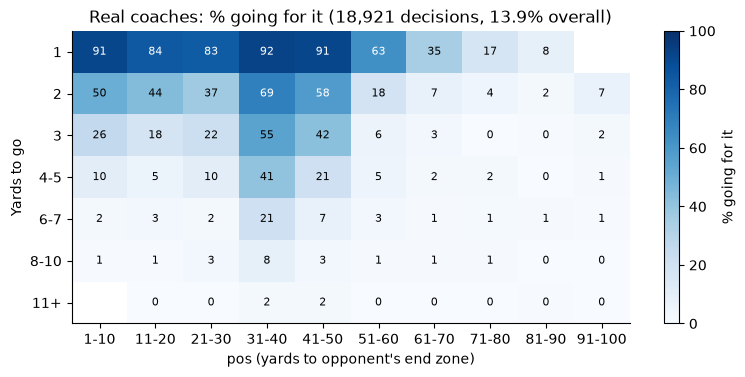

In [26]:
plots.coach_go_rates(params)

## 2. Does the simulator work?
A drive is a Markov chain on (down, yards to go, pos). A game is 11 drives per team, no clock.
**Coach vs coach** should give 50% (test of $H_0: p = 0.5$), and simulated $p(d)$ and drive outcomes should match the data.

Coach vs coach: p̂ = 0.4989 [0.4946, 0.5032], p-value = 0.61


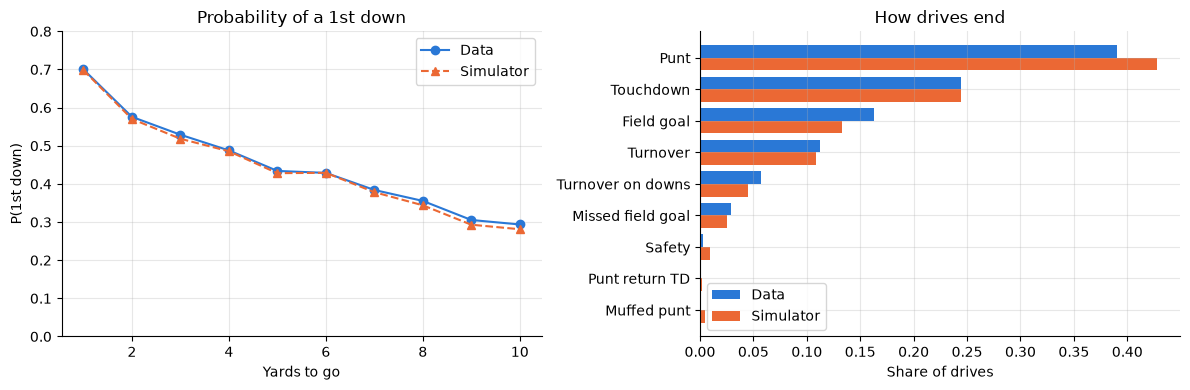

In [27]:
win_prob, lower, upper, p_value = results["coach_vs_coach"]
print(f"Coach vs coach: p̂ = {win_prob:.4f} [{lower:.4f}, {upper:.4f}], p-value = {p_value:.2f}")
plots.validation(results)

The p-value is far from significant, so the simulator has no built-in bias. A few more punts in the simulator,
because real drives also end at halftime, which we don't model.

## 3. Step 1: each strategy on its own
Each game is a Bernoulli trial (win 1, tie ½, loss 0). Game $i$ uses the same random numbers for every strategy,
so differences are **paired**: $D_i = X_i^A - X_i^B$, 95% CI by the CLT.

**How far should we try field goals?**

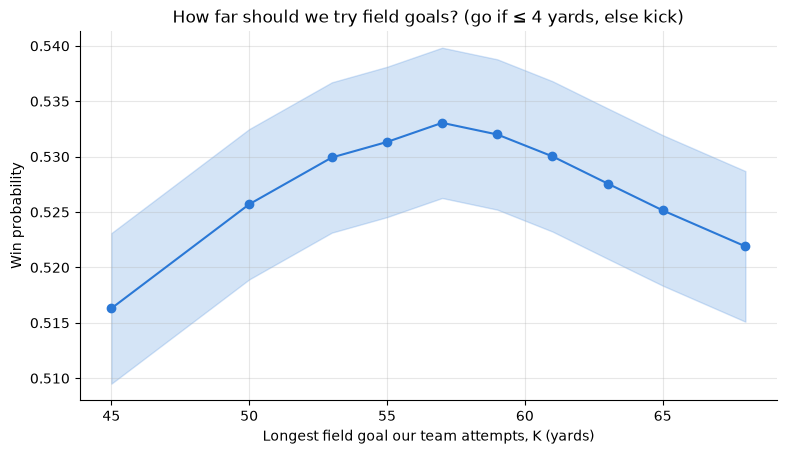

Best K = 57 yards, P(made) there = 55%


In [28]:
plots.fg_range_sweep(results)
print(f"Best K = {results['best_kick_distance']} yards, P(made) there = {params['p_field_goal'][results['fg_range']]:.0%}")

Trying longer field goals helps up to about 57 yards. Beyond that, a punt that pins the opponent deep is worth more
than the long kick (the curve is flat between 55 and 61 yards, so the exact limit hardly matters).

**Aggressiveness:** going for it at random (orange) never beats the coaches. Going for it on short yardage (blue) does:
**where** you go for it matters, not how often.

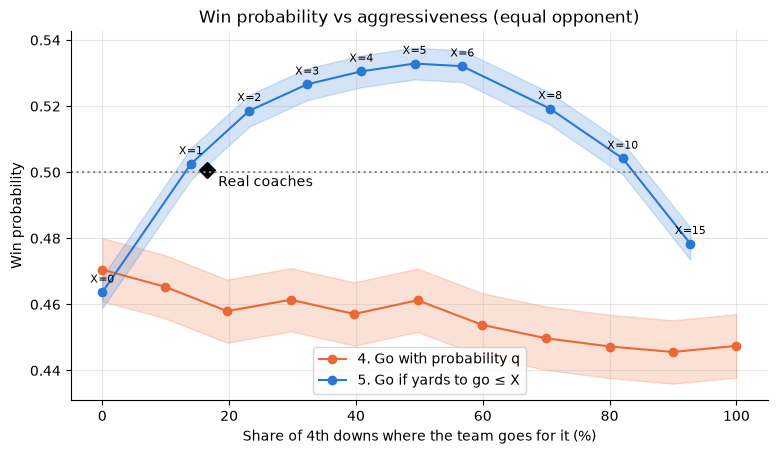

In [29]:
plots.aggressiveness(results)

**Short and close** (go if yards to go ≤ X and pos ≤ Y; X = 1–8, Y = 10–100 in 10-yard steps, Y = 100 is "go if ≤ X"
anywhere), 100,000 paired games per cell. Boxed: cells **not significantly worse than the best cell**. Only one cell is boxed:
**go if ≤ 6 yards, but never inside our own 30** (Y = 70), 53.5%. Down the rows the yards to go matter most (4th & 5–6 is best,
4th & 8 already worse); across the columns, going for it only near the opponent's goal clearly loses, and going for it deep
in our own end costs a little. The 5 best cells go into the combination search.

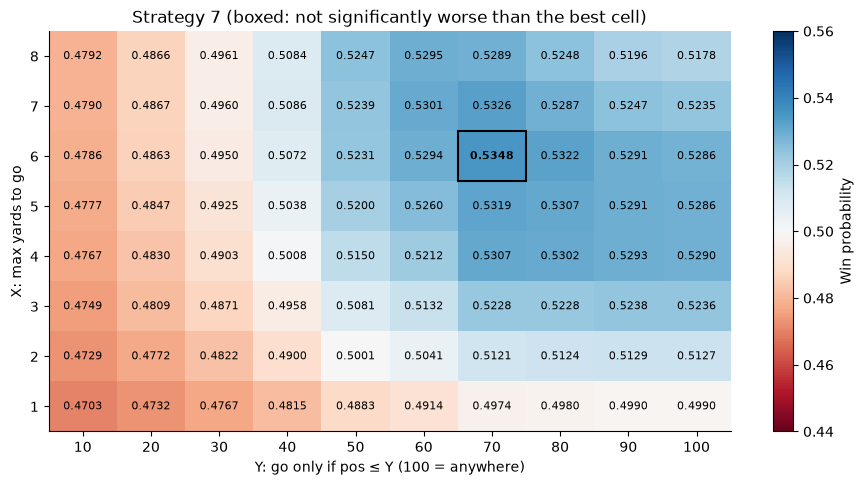

In [30]:
plots.short_close_heatmap(results)

**No man's land (dead zone):** about 35–55 yards from the end zone a field goal is unlikely and a punt gains little.
On top of "go if ≤ 5 yards", also going for it there with ≤ 10 yards to go adds up to about +0.9 pp (35–55). The heatmap uses
10,000 paired games per range, so neighbouring ranges are within noise. The 5 best ranges go into the combination search
(team choice: 25–55 was replaced by the next range, 40–55; the two are within noise).
Without a yards-to-go limit the rule would also go on 4th & 15, which converts only about 14% of the time.

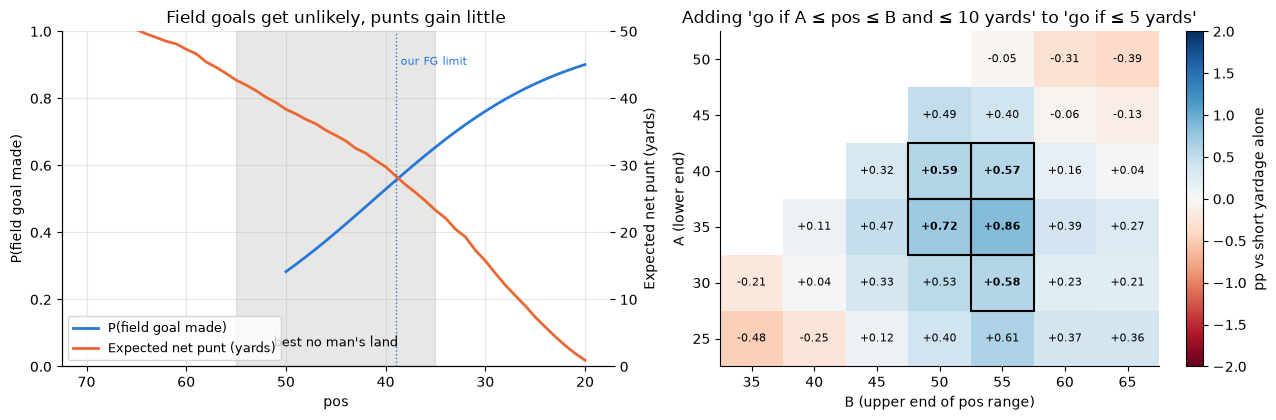

In [31]:
plots.dead_zone(params, results)

**Trailing late** (go when behind with ≤ N drives left), win probability:

In [32]:
results["trailing_sweep"].T.round(3)

,1,2,3,4,6,8,12
p̂,0.481,0.486,0.491,0.499,0.497,0.504,0.503


**All single strategies** (30,000 paired games). Only the yards-to-go rules beat the coaches on their own:
"go if ≤ 5 yards" gains about +3.1 pp, and "≤ 6 yards, never inside our own 30" about +3.6 pp. Never going for it (−4.1),
always going for it (−5.5), random going, the goal line and no man's land alone all lose.

**Score-changing field goal** (rule 12: with ≤ 3 drives left and in field-goal range, always kick when the field goal changes
the number of scores between the teams: up 6–8 → 9+, or down 9–11 → within 8) changes little: the situation is rare.

**Leading late** (rule 13: when ahead with ≤ 2 drives left, never go for it in our own half) adds about +0.4 pp on top of
"go if ≤ 5 yards" (+3.5 vs +3.1): a failed attempt there hands the opponent a short field for the winning score.

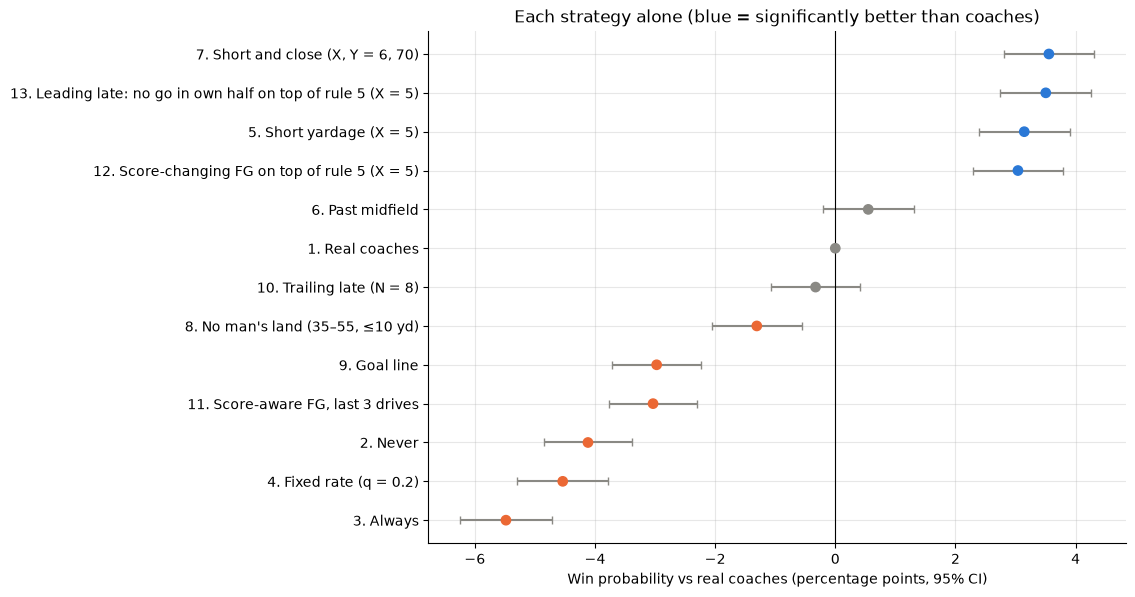

,p̂,diff (pp),diff lower,diff upper,go %
1. Real coaches,0.502,0.000,0.000,0.000,16.475
2. Never,0.461,-4.117,-4.855,-3.378,0.000
3. Always,0.447,-5.482,-6.243,-4.720,100.000
4. Fixed rate (q = 0.2),0.457,-4.537,-5.294,-3.780,19.918
5. Short yardage (X = 5),0.534,3.145,2.390,3.900,49.395
6. Past midfield,0.508,0.548,-0.206,1.302,46.108
"7. Short and close (X, Y = 6, 70)",0.538,3.555,2.800,4.310,49.420
"8. No man's land (35–55, ≤10 yd)",0.489,-1.307,-2.054,-0.560,21.535
9. Goal line,0.472,-2.973,-3.712,-2.235,2.964
10. Trailing late (N = 8),0.499,-0.328,-1.072,0.415,41.670


In [33]:
plots.strategy_diffs(results["singles"], "Each strategy alone (blue = significantly better than coaches)")
results["singles"].round(3)

## 4. Step 2: the best combination
**Successive halving:** play all candidates on 1,000 games, keep the best quarter, play the survivors on 4× more games, repeat
(1,000 → 4,000 → 16,000 → 64,000 games; 4× the games halves the standard error). Candidates: one of the 5 best strategy-7 cells,
one of the 5 dead-zone ranges (≤ 6 or ≤ 10 yards), goal line, trailing late (2, 3 or 6 drives), the score-changing field goal
(1, 2 or 3 drives) and leading late (off or ≤ 2 drives); otherwise kick. 4,224 candidates.

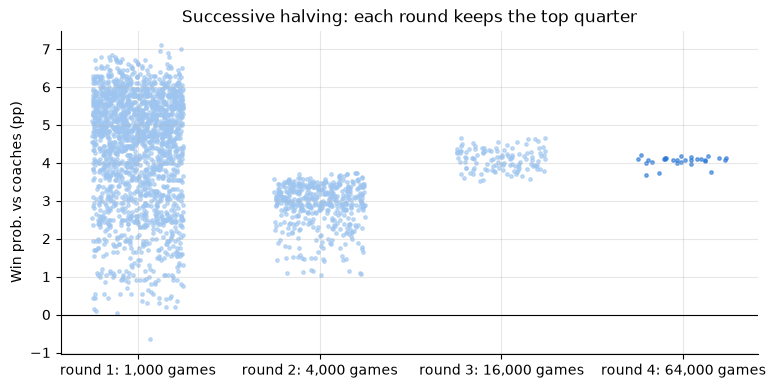

In [34]:
plots.halving(results)

**Which rules matter?** Regression of each candidate's gain on 0/1 indicators of its rules:
$\beta_r$ = average change in win probability from adding rule $r$.

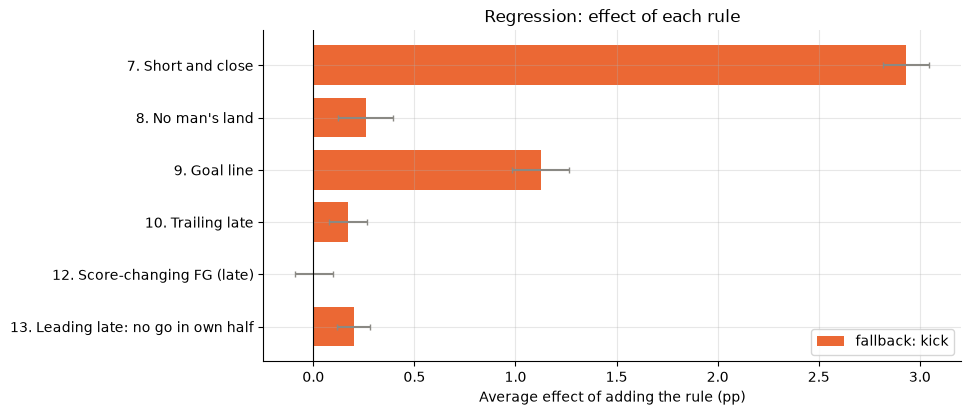

In [35]:
plots.effects(results)

**Final check** (50,000 paired games, fresh random numbers): the top 5 of the last round, the best single rule and the
coaches. The best of thousands of noisy candidates is usually a bit lucky (winner's curse), so the final check uses new games.
The best one (orange) is our strategy: **54.2%, +4.0 pp [3.4, 4.6] over the coaches, +1.3 pp [1.0, 1.6] over the best single rule.**

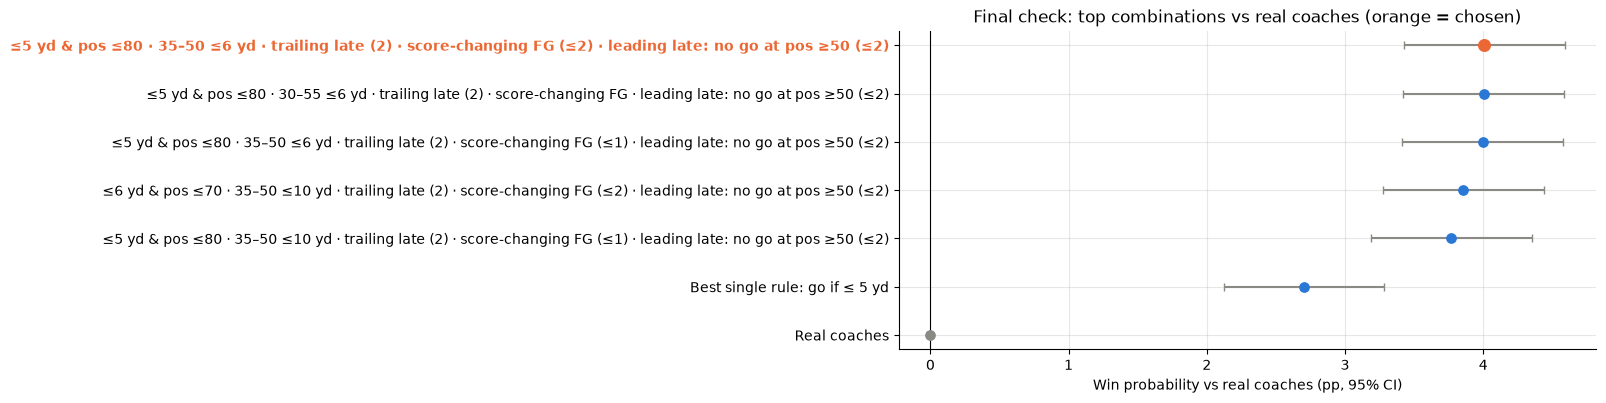

Best combination − best single rule = 1.31 pp [1.01, 1.61]


In [36]:
plots.final_check(results)
print("Best combination − best single rule = {:.2f} pp [{:.2f}, {:.2f}]".format(*results["best_vs_single"]))

**Why not go for it deep in our own end?** A failed attempt there hands the opponent a short field: their next drive scores
a touchdown about 2–3 times as often as after a punt. Net points over the rest of our drive and the opponent's next drive
(`scripts/deep_tradeoff.py`, 20,000 simulations per row): 4th & 1 still pays almost everywhere, but 4th & 2 and 4th & 4 inside our own
20 are worse than punting, which is why the best strategy never goes for it inside our own 20.

In [37]:
pd.read_csv(model.RESULTS_DIR / "deep_tradeoff.csv").set_index(["our own", "4th &"]).round(2)

P(convert)  opp TD after failed go  opp TD after punt  \
our own 4th &                                                          
1       1            0.69                    0.95               0.33   
        2            0.58                    0.94               0.33   
        4            0.48                    0.93               0.34   
5       1            0.70                    0.87               0.32   
        2            0.58                    0.86               0.31   
        4            0.49                    0.84               0.31   
10      1            0.69                    0.73               0.28   
        2            0.58                    0.74               0.28   
        4            0.48                    0.74               0.28   
20      1            0.69                    0.61               0.23   
        2            0.57                    0.61               0.24   
        4            0.48                    0.61               0.23   
30      1            0.70                    0.52               0.20   
        2            0.58                    0.52               0.20   
        4            0.49                    0.53               0.20   

               opp score after failed go  opp score after punt  net pts: go  \
our own 4th &                                                                 
1       1                           0.97                  0.51        -2.43   
        2                           0.96                  0.51        -2.91   
        4                           0.96                  0.52        -3.32   
5       1                           0.95                  0.48        -2.40   
        2                           0.95                  0.48        -2.83   
        4                           0.95                  0.48        -3.10   
10      1                           0.93                  0.44        -2.09   
        2                           0.93                  0.44        -2.59   
        4                           0.93                  0.43        -3.01   
20      1                           0.88                  0.36        -1.55   
        2                           0.89                  0.37        -2.08   
        4                           0.89                  0.36        -2.42   
30      1                           0.83                  0.30        -1.01   
        2                           0.83                  0.31        -1.54   
        4                           0.83                  0.30        -1.93   

               net pts: punt  go − punt (pts)  
our own 4th &                                  
1       1              -2.85             0.43  
        2              -2.84            -0.07  
        4              -2.87            -0.45  
5       1              -2.69             0.29  
        2              -2.67            -0.16  
        4              -2.66            -0.44  
10      1              -2.41             0.32  
        2              -2.42            -0.18  
        4              -2.41            -0.60  
20      1              -1.99             0.44  
        2              -2.01            -0.07  
        4              -1.98            -0.44  
30      1              -1.64             0.64  
        2              -1.68             0.14  
        4              -1.65            -0.28

## 5. Step 3: opponent strength
Strong / weak opponent = plays only from the top / bottom third of teams by EPA per play.
The stronger the opponent, the more aggression pays.

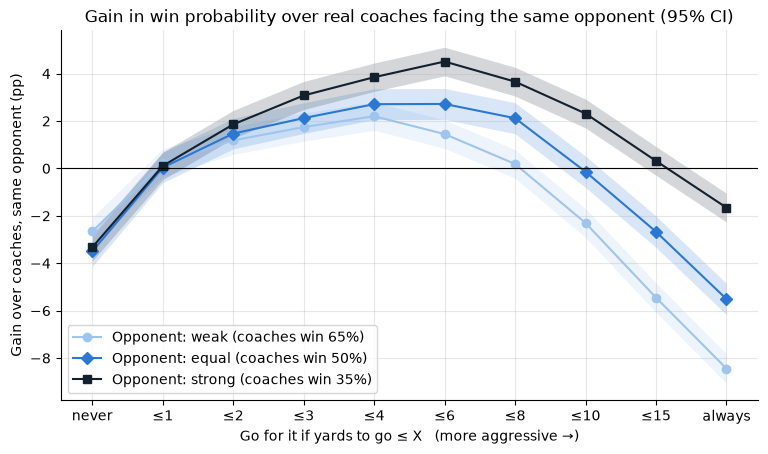

,weak,equal,strong
best single (≤5 yd),1.5,3.1,3.6
best combination,2.9,4.1,4.9


In [38]:
plots.opponents(results)
results["best_strategy_gain_by_opponent"].round(1)

**The best strategy for each opponent** (`scripts/opponents_search.py`): the same search against a weak and a strong opponent,
with that opponent's own heatmaps, the top 5 of each into successive halving and a final check on 50,000 fresh games.

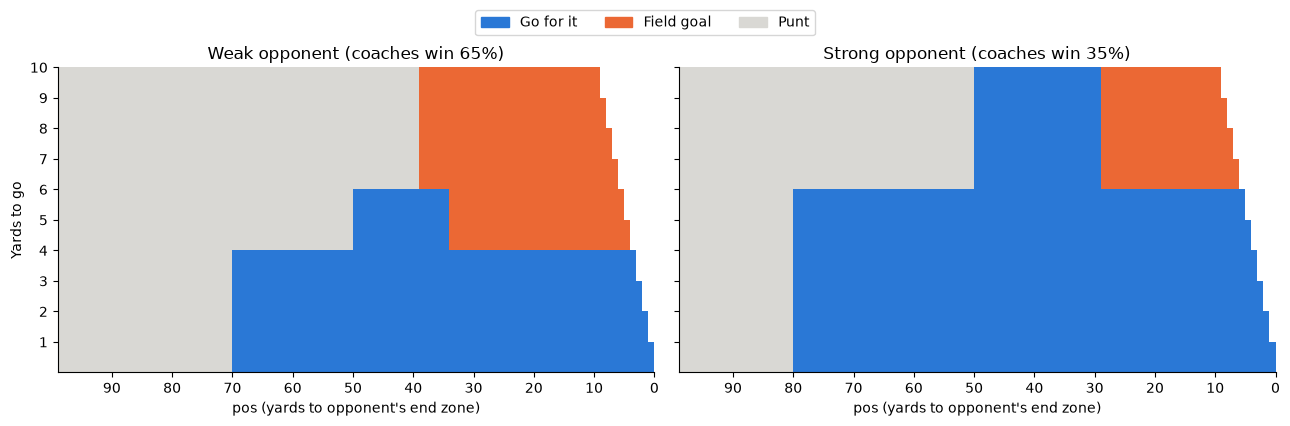

,weak,strong
coaches win,65%,35%
best strategy,≤4 yd & pos ≤70 + no man's land 35–50 (≤6 yd) ...,≤6 yd & pos ≤80 + no man's land 30–50 (≤10 yd)...
gain over coaches (pp),"+3.6 [3.0, 4.1]","+4.6 [4.1, 5.2]"


In [39]:
opponent_results = model.load_results("results_opponents.json")
search_opponents = ["weak", "strong"]
plots.handbook_pair({o: opponent_results[f"{o}/handbook"] for o in search_opponents},
                    {o: opponent_results[f"{o}/coaches"] for o in search_opponents})
pd.DataFrame({o: {"coaches win": f"{100 * opponent_results[f'{o}/coaches']:.0f}%",
                  "best strategy": opponent_results[f"{o}/best_name"],
                  "gain over coaches (pp)": "{:+.1f} [{:.1f}, {:.1f}]".format(
                      *opponent_results[f"{o}/final"].loc[opponent_results[f"{o}/best_name"],
                                                          ["diff (pp)", "diff lower", "diff upper"]])}
              for o in search_opponents})

## 6. The handbook
What the best strategy does on every 4th down in a normal situation (tied game, not late), next to what coaches usually do.

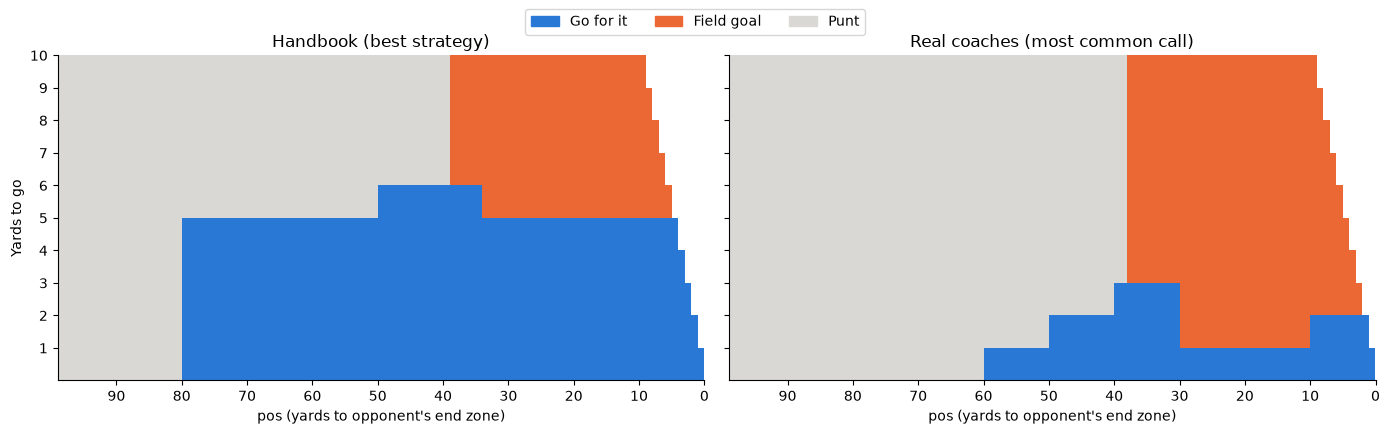

In [40]:
handbook_table = model.handbook(params, best_policy)
plots.handbook_map(handbook_table)

**The handbook in one table:** in each zone, go for it with this many yards to go or fewer.

In [41]:
model.go_thresholds(handbook_table)

,go if yards to go ≤,otherwise
pos (yards to end zone),,
1-10,5,fg
11-20,5,fg
21-30,5,fg
31-40,6,fg/punt
41-50,6,punt
51-60,5,punt
61-70,5,punt
71-80,5,punt
81-90,never,punt


**Look up any situation** (change the numbers):

In [42]:
handbook_table.query("yards_to_go == 4 and yards_to_endzone == 55").round(2)

,yards_to_go,yards_to_endzone,call,P(1st down),FG distance,P(FG good),coaches go %,coaches usually
345,4,55,go,0.49,73,0.0,5.04,punt


## 7. Conclusions
1. Both extremes lose, and so does random aggressiveness: **where** you go for it matters, not how often.
2. Short yardage is the main driver: "go if ≤ 5 yards to go" alone gives about +3 pp.
3. Field goals pay up to about 57 yards; beyond that, punting is worth more.
4. The best combination (≤ 5 yards but never inside our own 20, ≤ 6 yards in the dead zone 35–50, trailing late, a score-changing
   field goal late, and no attempts in our own half when leading late) wins **54.2%, +4.0 pp** over the coaches,
   +1.3 pp more than the best single rule.
5. The handbook is far bolder than real coaches: it goes for it on 4th & up to 5 from our own 20; coaches mostly on 4th & 1–3
   in the opponent's half.
6. The stronger the opponent, the more aggression pays: the best strategy gains +3.6 pp against a weak team (4th & ≤ 4, never
   inside our own 30) and +4.6 pp against a strong team (4th & ≤ 6 from our own 20, up to 10 in the dead zone).
7. Robustness: with score-aware coaches (their real 4th-quarter decisions per score state) the gain falls only from 4.0 to 3.6 pp.

**Caveats:** no clock or penalties; the opponent does not adapt; 4th downs modelled with 3rd-down plays; the simulated coaches use
their quarter 1–3 behaviour all game; opponent strength only affects its offense; the return yards of a punt are added to the
punt. Results compare strategies; they are not exact win probabilities.